<a href="https://colab.research.google.com/github/xiimahaa/NLP_Lab11/blob/main/Lab_11_Attention_with_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [3]:
from google.colab import files

uploaded = files.upload()

Saving Lab_11_QnA_Dataset.csv to Lab_11_QnA_Dataset.csv


In [4]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")

print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())

display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [5]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [6]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

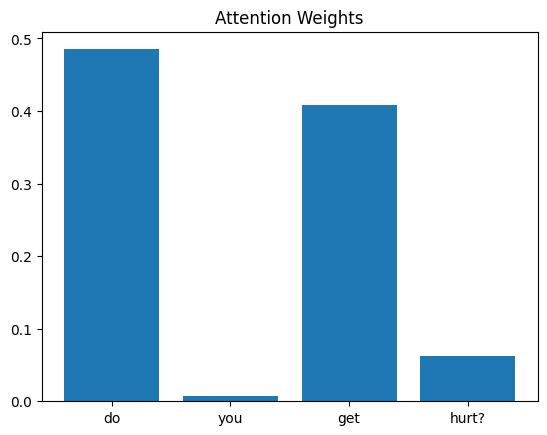

In [8]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question 1: do you get hurt?
Highest attention word: do
Attention weight: 0.4851
--------------------------------------------------
Question 2: do you have fingers?
Highest attention word: do
Attention weight: 0.8270
--------------------------------------------------
Question 3: do you ever breathe
Highest attention word: do
Attention weight: 0.6996
--------------------------------------------------


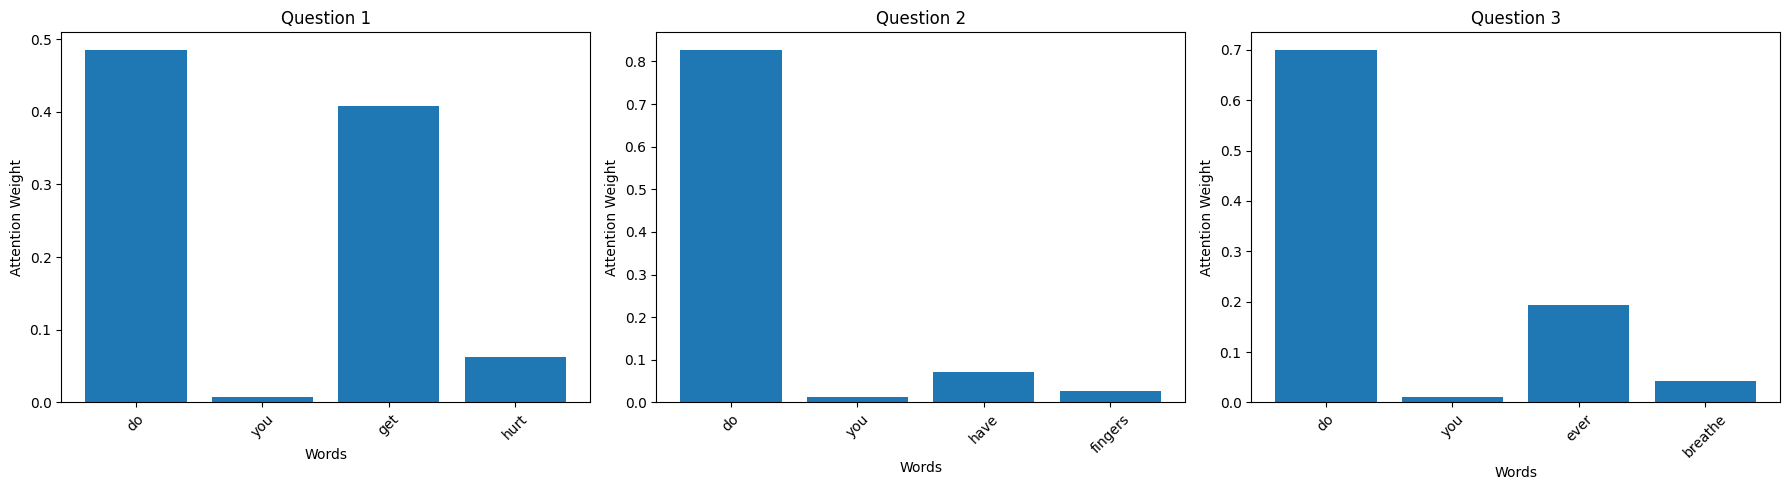

In [9]:
model.eval()

selected_indices = [0, 1, 2]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, idx in enumerate(selected_indices):
    question = df["question"].iloc[idx]

    words = tokenizer.sequences_to_texts([X[idx].tolist()])[0].split()

    with torch.no_grad():
        prediction, weights = model(X[idx:idx+1])

    attention_weights = weights[0, :len(words)].numpy()

    max_index = attention_weights.argmax()
    important_word = words[max_index]

    print(f"Question {i+1}: {question}")
    print(f"Highest attention word: {important_word}")
    print(f"Attention weight: {attention_weights[max_index]:.4f}")
    print("-" * 50)

    axes[i].bar(words, attention_weights)
    axes[i].set_title(f"Question {i+1}")
    axes[i].set_xlabel("Words")
    axes[i].set_ylabel("Attention Weight")
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


Not always. In "will you ask me anything about myself", the top word was "myself", which is meaningful. However, in "do you get hurt?", the top word was "do", and in "are you old?", it was "you". These words appear in many questions, so they do not really help identify the meaning. The important words, such as "hurt" and "old", received lower attention weights.

I think this may be because the model is small and was trained for only 50 epochs. Also, since the RNN processes words in sequence, earlier words can carry information about the whole question. This means that attention weights do not always match what humans consider the most important words. They only give us an idea of which words the model focuses on.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

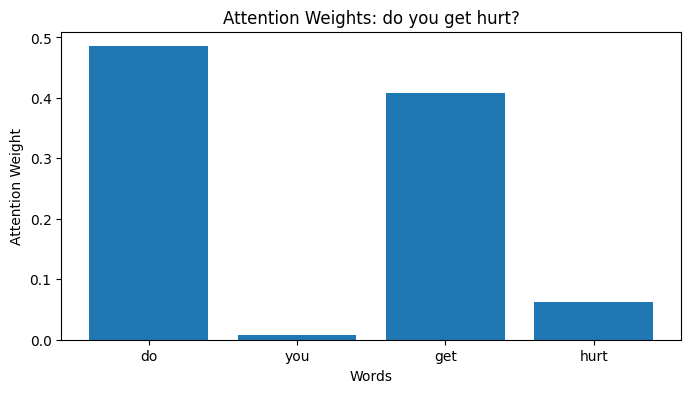

Highest attention word: do


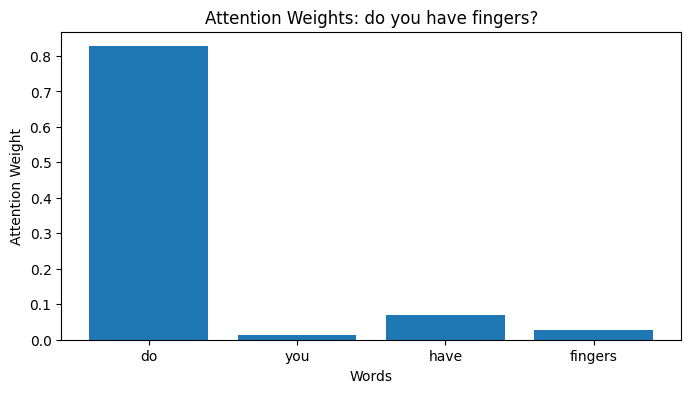

Highest attention word: do
Question A focuses on: do
Question B focuses on: do


In [16]:
qa = 0
qb = 1

def plot_attention(idx):
    question = df["question"].iloc[idx]
    words = tokenizer.sequences_to_texts([X[idx].tolist()])[0].split()

    with torch.no_grad():
        prediction, weights = model(X[idx:idx+1])

    attention = weights[0, :len(words)].numpy()

    plt.figure(figsize=(8, 4))
    plt.bar(words, attention)
    plt.title(f"Attention Weights: {question}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.show()

    highest_word = words[attention.argmax()]
    print("Highest attention word:", highest_word)

    return highest_word

word_a = plot_attention(qa)
word_b = plot_attention(qb)

print("Question A focuses on:", word_a)
print("Question B focuses on:", word_b)


I compared "do you get hurt?" and "do you have fingers?". Both questions have the same expected answer, but use different wording. The model focused on different words in each question. In the first question, it focused on "do", while in the second question, it focused on "have".

This shows that attention is not fixed. It is calculated again for each question, so the model can focus on different words even when the expected answer is the same. It also shows that attention does not always focus on the words that humans consider the most important.